# Russian auxiliary corpus: audit and experiment

Full-file structural and duplicate census; 100-context AI review; nine controlled recurrent runs. No calibration, final audit, or test-label scores. See `reports/RUSSIAN_CORPUS_ANALYSIS.md` for definitions, costs and limits.

In [5]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
BASE = Path.cwd() if (Path.cwd() / 'reports/ru_corpus_split_audit.json').exists() else Path.cwd() / 'assignment3'
BASE = BASE.resolve()
audit = json.loads((BASE / 'reports/ru_full_structural_audit.json').read_text())
print('Full Russian rows:', audit['counts']['rows'])
display(pd.Series(audit['counts']))
display(pd.read_csv(BASE / 'reports/ru_validation_partitions.csv'))

Full Russian rows: 8028840


LOC_edge_whitespace         13
LOC_overlap                  0
LOC_duplicate_spans          0
LOC_ORG_overlaps             9
LOC_PER_overlaps            10
rows                   8028840
LOC_mentions           3708173
positive_rows          2464436
bio_eligible_rows      8022071
empty_text_rows              0
has_newline                  0
has_latin              1364573
has_ua_specific            799
has_ru_specific        6550835
has_astral                 692
missing_doc_id               0
missing_sent_id              0
LOC_partial_token         7712
dtype: int64

,partition,rows,documents,LOC_mentions,empty_LOC_fraction
0,excluded_RU_duplicate,170104,80596,76097.0,0.715304
1,excluded_RU_valid_overlap_doc,1602493,132569,759620.0,0.691609
2,excluded_alignment,5148,2449,7479.0,0.000000
3,excluded_label_conflict,6346,4959,8756.0,0.286637
4,ru_fit,5440386,532263,2484003.0,0.694006
5,ru_valid,804363,73953,372218.0,0.692414


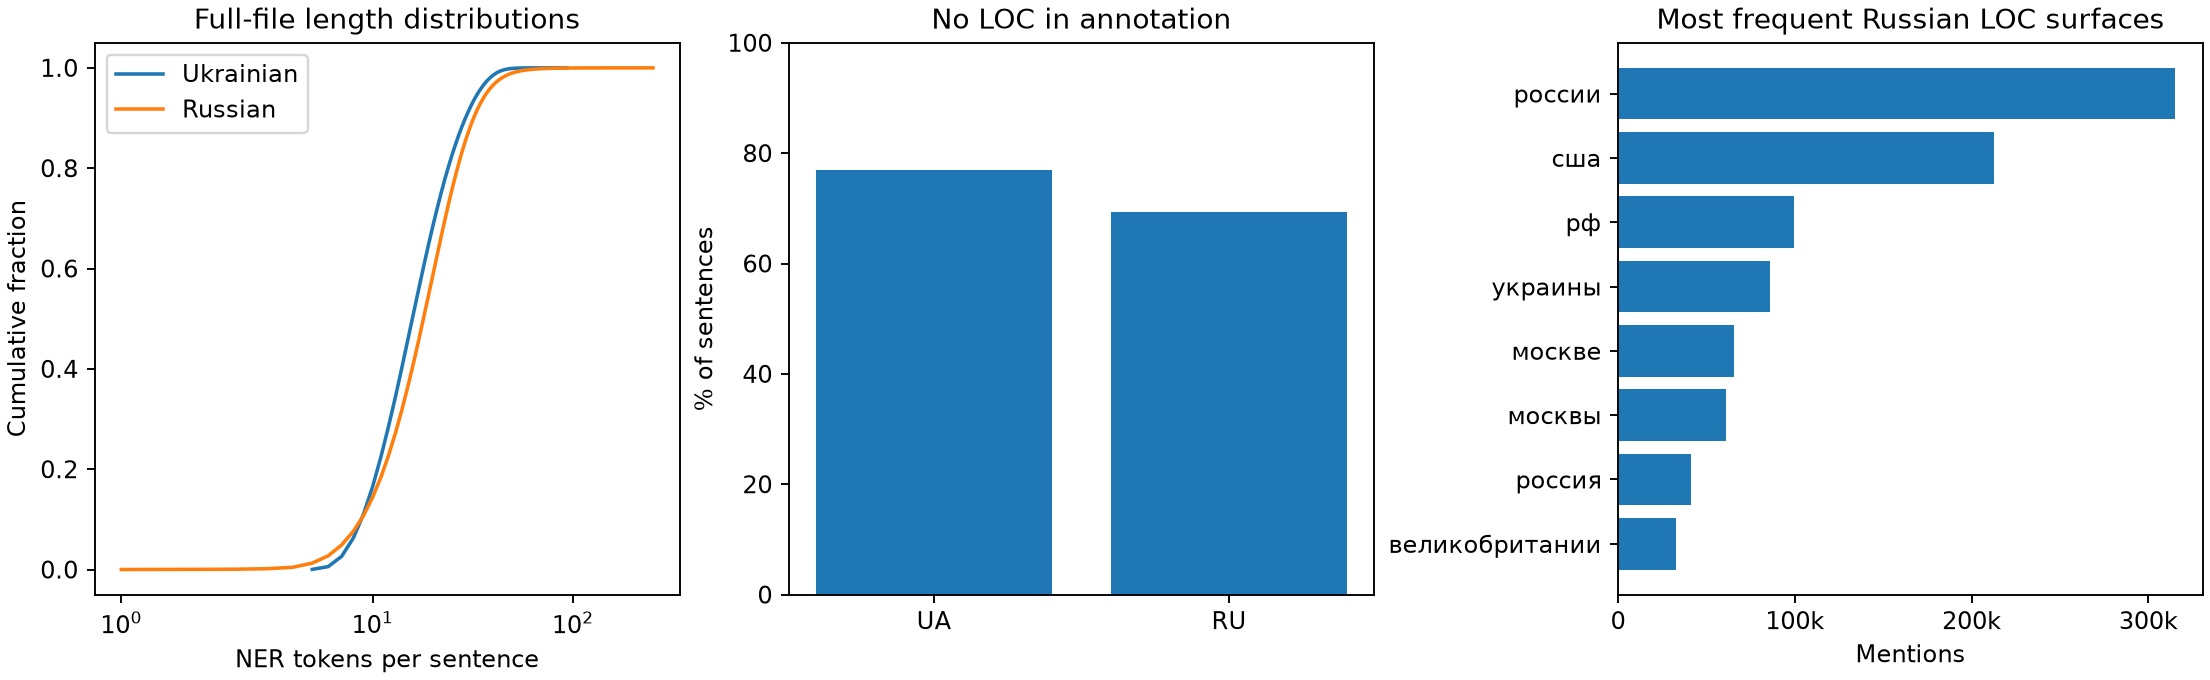

In [6]:
display(Image(filename=str(BASE / 'figures/ru_corpus_overview.png')))

In [7]:
display(pd.read_csv(BASE / 'reports/ru_augmentation_runs.csv'))
display(pd.read_csv(BASE / 'reports/ru_augmentation_summary.csv'))

,seed,arm,fit_rows,vocabulary_size,optimizer_updates,best_epoch,checkpoint_f1,checkpoint_precision,checkpoint_recall,checkpoint_span_f1,checkpoint_OOV,ru_diagnostic_f1,ru_diagnostic_precision,ru_diagnostic_recall,train_monitor_f1,seconds,fit_positive_rows,fit_LOC_mentions,fit_tokens
0,42,UA_12k,12000,30002,1504,8,0.568226,0.491685,0.672989,0.562540,0.143613,0.209857,0.164179,0.290749,0.813065,24.151140,2715,3962,217802
1,42,UA_12k_plus_RU_12k,24000,30002,3000,6,0.613201,0.576000,0.655539,0.610837,0.167373,0.715811,0.664778,0.775330,0.796574,40.740654,6354,9351,464372
2,42,UA_12k_plus_UA_12k,24000,30002,3000,8,0.684871,0.666667,0.704097,0.679356,0.123720,0.250000,0.287143,0.221366,0.874251,41.726561,5417,8041,434202
3,43,UA_12k,12000,30002,1504,7,0.584945,0.536755,0.642640,0.579452,0.143613,0.178814,0.122128,0.333700,0.813970,23.232137,2715,3962,217802
4,43,UA_12k_plus_RU_12k,24000,30002,3000,8,0.640453,0.600664,0.685888,0.633427,0.167373,0.742736,0.713706,0.774229,0.860294,45.504768,6354,9351,464372
5,43,UA_12k_plus_UA_12k,24000,30002,3000,7,0.676653,0.652572,0.702580,0.673181,0.123720,0.252800,0.245088,0.261013,0.879401,44.968890,5417,8041,434202
6,44,UA_12k,12000,30002,1504,8,0.578135,0.518029,0.654021,0.569910,0.143613,0.182772,0.121960,0.364537,0.832861,29.251578,2715,3962,217802
7,44,UA_12k_plus_RU_12k,24000,30002,3000,7,0.615838,0.598425,0.634294,0.612349,0.167373,0.751586,0.722561,0.783040,0.845873,49.863041,6354,9351,464372
8,44,UA_12k_plus_UA_12k,24000,30002,3000,8,0.679392,0.636003,0.729135,0.676244,0.123720,0.233166,0.214418,0.255507,0.869757,50.611516,5417,8041,434202


,arm,checkpoint_mean,checkpoint_sd,ru_mean,oov_mean
0,UA_12k,0.577102,0.008407,0.190481,0.143613
1,UA_12k_plus_RU_12k,0.623164,0.015031,0.736711,0.167373
2,UA_12k_plus_UA_12k,0.680305,0.004184,0.245322,0.123720


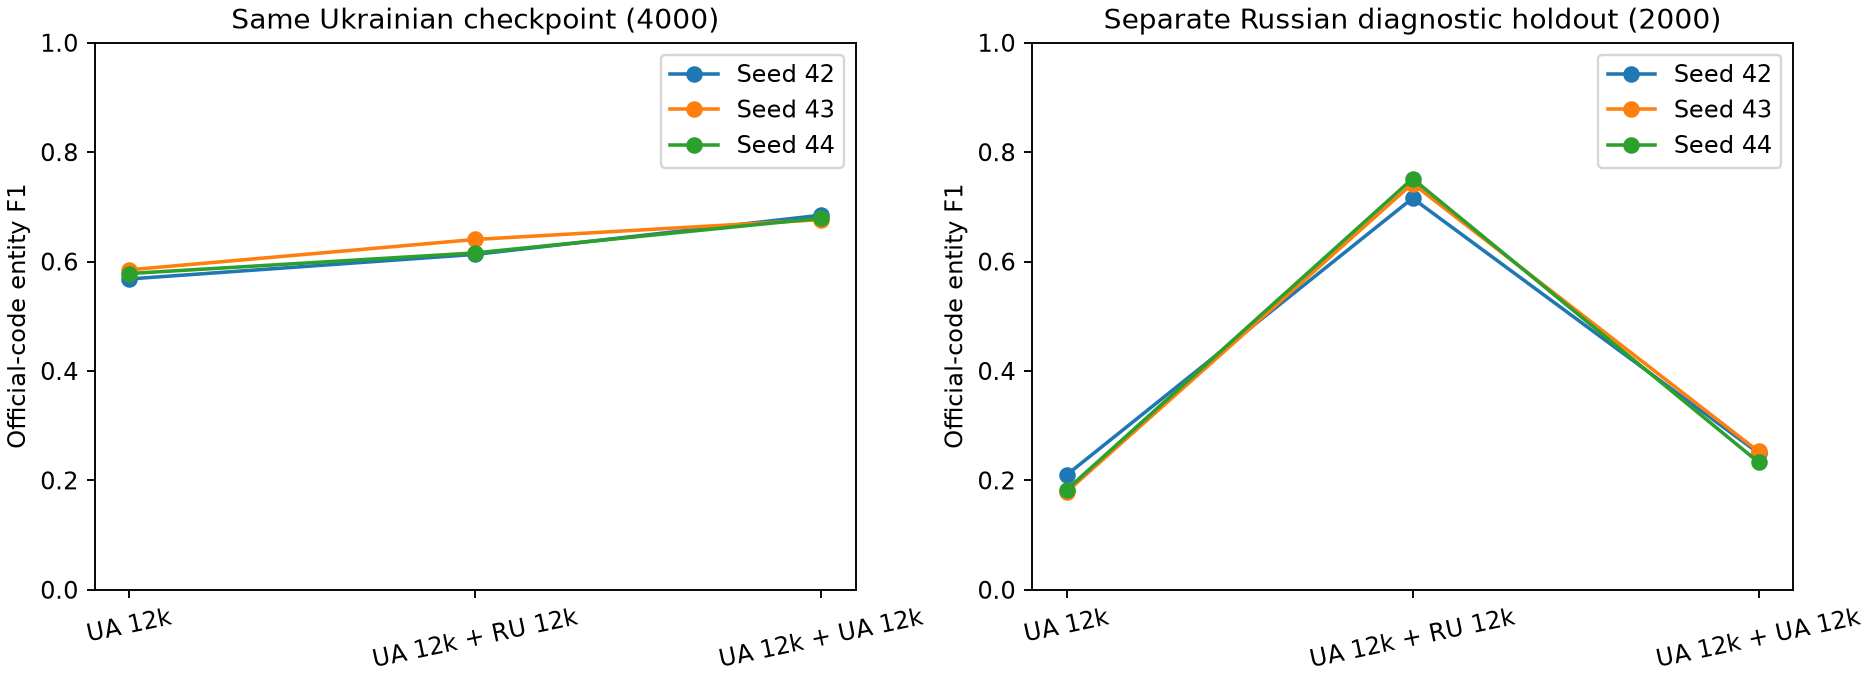

In [8]:
display(Image(filename=str(BASE / 'figures/ru_augmentation_experiment.png')))